In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

In [2]:
# stocks
tickers = ['SPY', 'LLOY.L', 'BP.L', 'AAPL', '^FTSE', 'META', 'PLTR', 'TSLA']

# downloading market data
raw = yf.download(tickers, start='2021-01-01', end='2024-12-31')
prices = raw['Close']
print(prices.head())
print(prices.shape)


[*********************100%***********************]  8 of 8 completed

Ticker            AAPL        BP.L     LLOY.L        META       PLTR  \
Date                                                                   
2021-01-04  125.632523  253.777252  34.742664  266.388611  23.370001   
2021-01-05  127.185768  271.726135  35.116676  268.399323  24.600000   
2021-01-06  122.904518  288.976959  37.061508  260.812012  23.540001   
2021-01-07  127.098412  294.162109  36.792217  266.190521  25.000000   
2021-01-08  128.195435  297.851746  36.727390  265.031647  25.200001   

Ticker             SPY        TSLA        ^FTSE  
Date                                             
2021-01-04  341.588684  243.256668  6571.899902  
2021-01-05  343.941345  245.036667  6612.299805  
2021-01-06  345.997589  251.993332  6841.899902  
2021-01-07  351.138245  272.013336  6857.000000  
2021-01-08  353.138977  293.339996  6873.299805  
(1029, 8)


In [3]:
# calculating log returns
log_return = np.log(prices / prices.shift(1)).dropna()
print(log_return)

Ticker          AAPL      BP.L    LLOY.L      META      PLTR       SPY  \
Date                                                                     
2021-01-05  0.012288  0.068338  0.010708  0.007520  0.051293  0.006864   
2021-01-06 -0.034241  0.061552  0.053903 -0.028676 -0.044045  0.005961   
2021-01-07  0.033554  0.017784 -0.007293  0.020412  0.060175  0.014748   
2021-01-08  0.008594  0.012465 -0.001764 -0.004363  0.007968  0.005682   
2021-01-11 -0.023524  0.000334 -0.018085 -0.040928  0.028557 -0.006764   
...              ...       ...       ...       ...       ...       ...   
2024-12-19  0.006990 -0.011411 -0.009531 -0.002717  0.037062 -0.000307   
2024-12-20  0.018641  0.000000 -0.001843 -0.017480  0.081979  0.011940   
2024-12-23  0.003060  0.004344 -0.004438  0.024640  0.001737  0.005970   
2024-12-24  0.011413  0.001444  0.004807  0.013084  0.020728  0.011054   
2024-12-30 -0.013352  0.003367  0.001103 -0.014391 -0.024320 -0.011477   

Ticker          TSLA     ^FTSE  
Date

In [4]:
# visualising log returns
fig = px.line(log_return, 
              x=log_return.index, 
              y=log_return.columns,
              title='daily log returns by stock',
              labels={'value': 'daily log return', 'index': 'date', 'variable': 'ticker'})
fig.update_yaxes(range=[-0.3,0.3])
fig.show()

In [5]:
# calculating annualised return, annualised volatility, and sharpe ratio
trading_days = 252

summary = pd.DataFrame({
    'annualised_return': log_return.mean() * trading_days,
    'annualised_volatility': log_return.std() * np.sqrt(trading_days),
})

summary['sharpe_ratio'] = summary['annualised_return'] / summary['annualised_volatility']
summary = summary.round(4)
print(summary)

        annualised_return  annualised_volatility  sharpe_ratio
Ticker                                                        
AAPL               0.2160                 0.2661        0.8115
BP.L               0.0978                 0.2808        0.3483
LLOY.L             0.0776                 0.2695        0.2877
META               0.1594                 0.4599        0.3466
PLTR               0.3505                 0.6606        0.5306
SPY                0.1559                 0.1663        0.9375
TSLA               0.1124                 0.5966        0.1885
^FTSE              0.0529                 0.1267        0.4175


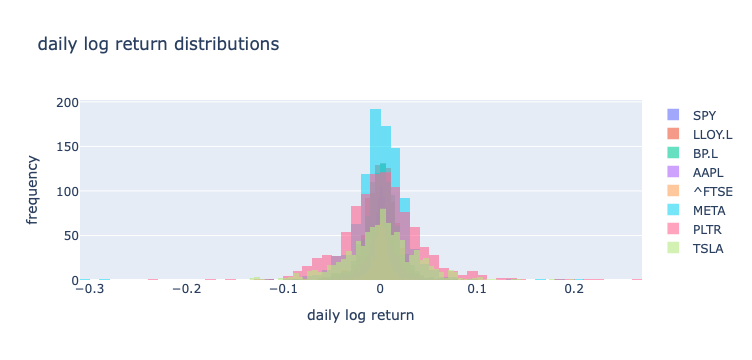

In [6]:
# visualising the distribution of returns
distribution = go.Figure()

for ticker in tickers:
    distribution.add_trace(go.Histogram(x=log_return[ticker],
                                        name = ticker,
                                        opacity = 0.6,
                                        nbinsx = 80
                                       ))
distribution.update_layout(
    barmode = 'overlay',
    title = 'daily log return distributions',
    xaxis_title = 'daily log return',
    yaxis_title = 'frequency'
)
distribution.show()

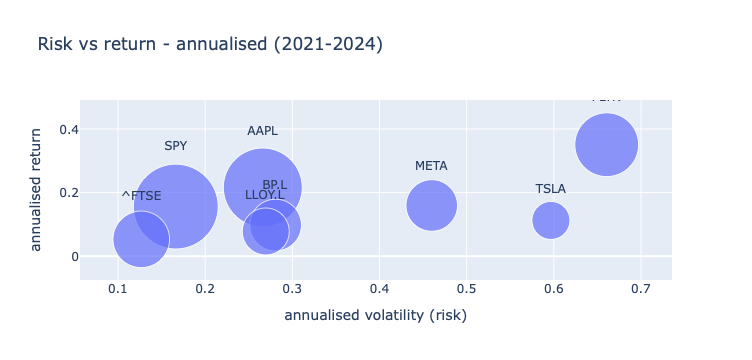

In [7]:
fig_scatter = px.scatter(
    summary.reset_index(),
    x='annualised_volatility',
    y='annualised_return',
    size='sharpe_ratio',
    text='Ticker',
    title='Risk vs return - annualised (2021-2024)',
    labels={
        'annualised_volatility': 'annualised volatility (risk)',
        'annualised_return': 'annualised return',
        'Ticker': 'ticker'

    },
    size_max=60

)
fig_scatter.update_traces(textposition='top center')
fig_scatter.show()

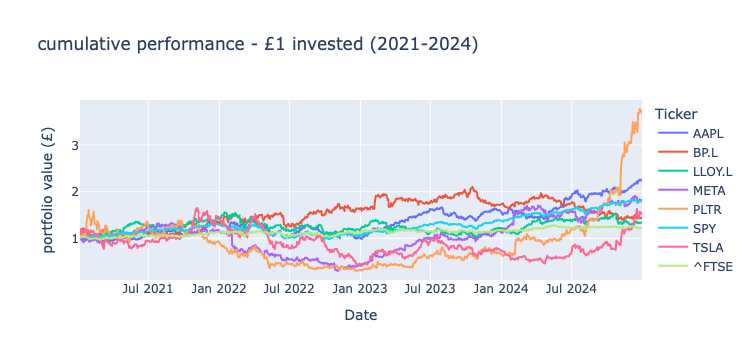

In [8]:
cumulative = np.exp(log_return.cumsum())

fig_cumulative = px.line(
    cumulative,
    x=cumulative.index,
    y=cumulative.columns,
    title='cumulative performance - £1 invested (2021-2024)',
    labels={'value': 'portfolio value (£)', 'index': 'date', 'variable': 'ticker'}
)
fig_cumulative.show()